In [35]:
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import train_test_split

from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense

In [36]:
df= pd.read_csv('data/data.csv')

df.drop(columns=['id','Unnamed: 32'],inplace=True)

df['diagnosis']=df['diagnosis'].map({
    'M':0,
    'B':1
})


C:\Users\saura\AppData\Local\Temp\ipykernel_13120\1838590856.py:3: Pandas4Warning: The inplace keyword in DataFrame.drop is deprecated and will be removed in a future version (PDEP-8).
See https://pandas.pydata.org/docs/dev/whatsnew/v3.1.0.html#deprecation-inplace for more details.
  df.drop(columns=['id','Unnamed: 32'],inplace=True)


In [37]:
X=df.drop(columns='diagnosis')
Y=df['diagnosis']



In [38]:
x_train,x_test,y_train,y_test =train_test_split(X,Y,test_size=0.2)

scaler=StandardScaler()

x_train=scaler.fit_transform(x_train)
x_test=scaler.transform(x_test)

x_train.shape

(455, 30)

In [39]:
model=Sequential([
    Dense(10,activation='relu',input_shape=(x_train.shape[1],)), #Input Layer
    Dense(10,activation='relu'), # Hidden layer
    Dense(1,activation='sigmoid') # Remove the activation or set to 
])

c:\Users\saura\Documents\Python\python_55_days_programs\deep_learning\venv\Lib\site-packages\keras\src\layers\core\dense.py:107: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


In [40]:
model.compile(
    optimizer='adam',
    loss='binary_crossentropy',
    metrics=['accuracy']
)

In [41]:
history=model.fit(
    x_train,
    y_train,
    epochs=100,
    batch_size=16,
    validation_data=(x_test,y_test)
)

Epoch 1/100


29/29 ━━━━━━━━━━━━━━━━━━━━ 1s 8ms/step - accuracy: 0.7495 - loss: 0.6286 - val_accuracy: 0.9123 - val_loss: 0.5499
Epoch 2/100
29/29 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - accuracy: 0.9121 - loss: 0.4885 - val_accuracy: 0.9386 - val_loss: 0.4057
Epoch 3/100
29/29 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - accuracy: 0.9319 - loss: 0.3551 - val_accuracy: 0.9474 - val_loss: 0.2824
Epoch 4/100
29/29 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - accuracy: 0.9363 - loss: 0.2581 - val_accuracy: 0.9561 - val_loss: 0.2011
Epoch 5/100
29/29 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - accuracy: 0.9451 - loss: 0.2012 - val_accuracy: 0.9649 - val_loss: 0.1580
Epoch 6/100
29/29 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - accuracy: 0.9451 - loss: 0.1686 - val_accuracy: 0.9737 - val_loss: 0.1324
Epoch 7/100
29/29 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - accuracy: 0.9538 - loss: 0.1483 - val_accuracy: 0.9737 - val_loss: 0.1121
Epoch 8/100
29/29 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - accuracy: 0.9604 - loss: 0.1329 - val_accuracy: 0.9649 - val_loss: 0.0

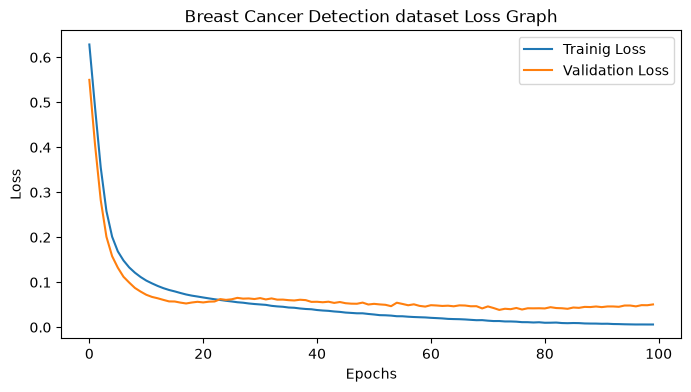

In [42]:
plt.figure(figsize=(8,4))
plt.plot(history.history['loss'],label='Trainig Loss')
plt.plot(history.history['val_loss'],label='Validation Loss')
plt.title("Breast Cancer Detection dataset Loss Graph")
plt.xlabel("Epochs")
plt.ylabel("Loss")
plt.legend()

In [ ]:
from tensorflow.keras.datasets import mnist

(x_train,x_test),(y_train,y_test)=mnist.load_data()


 1277952/11490434 ━━━━━━━━━━━━━━━━━━━━ 41s 4us/step

KeyboardInterrupt: 